# Xây dựng mô hình nhận diện chuỗi chữ số viết tay

## 1. Cấu hình

In [1]:
import sys
sys.path.append('..')
import matplotlib.pyplot as plt

from keras.optimizers import AdamW
from keras.callbacks import EarlyStopping, ReduceLROnPlateau
from models.DaiModel import build_dai_model

from utils.data import IMG_SHAPE, VOCAB_SIZE, MAX_SEQ_LEN, load_data
from utils.evaluate import predict_sequences, evaluate_model

## 2. Chuẩn bị dữ liệu

In [2]:
(X_train, train_in, train_out), (X_val, val_in, val_out), (X_test, y_test) = load_data()
print('Train:', X_train.shape, '| Val:', X_val.shape, '| Test:', X_test.shape)

Train: (42000, 28, 224, 1) | Val: (9000, 28, 224, 1) | Test: (9000, 28, 224, 1)


## 3. Xây dựng & Huấn luyện mô hình

In [ ]:
early_stopping = EarlyStopping(
    monitor='val_loss', 
    patience=5, 
    restore_best_weights=True
)

reduce_lr = ReduceLROnPlateau(
    monitor='val_loss', 
    factor=0.2, 
    patience=2, 
    min_lr=1e-7
)

callbacks = [early_stopping, reduce_lr]

In [4]:
model = build_dai_model(IMG_SHAPE, VOCAB_SIZE, MAX_SEQ_LEN)
model.compile(optimizer=AdamW(1e-3), loss='sparse_categorical_crossentropy', metrics=['accuracy'])
model.summary()

Model: "Dai_CRNN_Seq2Seq"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ image_input         │ (None, 28, 224,   │          0 │ -                 │
│ (InputLayer)        │ 1)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d (Conv2D)     │ (None, 28, 224,   │        144 │ image_input[0][0] │
│                     │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalization │ (None, 28, 224,   │         64 │ conv2d[0][0]      │
│ (BatchNormalizatio… │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation          │ (None, 28, 224,   │          0 │ batch_normalizat… │
│ (Activation)        │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d       │ (None, 28, 224,   │          0 │ activation[0][0]  │
│ (MaxPooling2D)      │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_1 (Conv2D)   │ (None, 28, 224,   │      4,608 │ max_pooling2d[0]… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 28, 224,   │        128 │ conv2d_1[0][0]    │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_1        │ (None, 28, 224,   │          0 │ batch_normalizat… │
│ (Activation)        │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_1     │ (None, 14, 112,   │          0 │ activation_1[0][… │
│ (MaxPooling2D)      │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_2 (Conv2D)   │ (None, 14, 112,   │     18,432 │ max_pooling2d_1[… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 14, 112,   │        256 │ conv2d_2[0][0]    │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_2        │ (None, 14, 112,   │          0 │ batch_normalizat… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_2     │ (None, 7, 56, 64) │          0 │ activation_2[0][… │
│ (MaxPooling2D)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_3 (Conv2D)   │ (None, 7, 56,     │     73,728 │ max_pooling2d_2[… │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 7, 56,     │        512 │ conv2d_3[0][0]    │
│ (BatchNormalizatio… │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_3        │ (None, 7, 56,     │          0 │ batch_normalizat… │
│ (Activation)        │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ decoder_input       │ (None, 9)         │          0 │ -               

 Total params: 238,461 (931.49 KB)

 Trainable params: 237,981 (929.61 KB)

 Non-trainable params: 480 (1.88 KB)

In [5]:
history = model.fit(
    [X_train, train_in], train_out,
    validation_data=([X_val, val_in], val_out),
    batch_size=128,
    epochs=20,
    callbacks=callbacks
)

Epoch 1/30
329/329 ━━━━━━━━━━━━━━━━━━━━ 164s 485ms/step - accuracy: 0.6162 - loss: 1.1126 - val_accuracy: 0.4055 - val_loss: 3.4175 - learning_rate: 0.0010
Epoch 2/30
329/329 ━━━━━━━━━━━━━━━━━━━━ 160s 485ms/step - accuracy: 0.9738 - loss: 0.1168 - val_accuracy: 0.9923 - val_loss: 0.0396 - learning_rate: 0.0010
Epoch 3/30
329/329 ━━━━━━━━━━━━━━━━━━━━ 164s 499ms/step - accuracy: 0.9957 - loss: 0.0219 - val_accuracy: 0.9955 - val_loss: 0.0195 - learning_rate: 0.0010
Epoch 4/30
329/329 ━━━━━━━━━━━━━━━━━━━━ 163s 495ms/step - accuracy: 0.9972 - loss: 0.0125 - val_accuracy: 0.9946 - val_loss: 0.0208 - learning_rate: 0.0010
Epoch 5/30
329/329 ━━━━━━━━━━━━━━━━━━━━ 163s 495ms/step - accuracy: 0.9982 - loss: 0.0078 - val_accuracy: 0.9970 - val_loss: 0.0106 - learning_rate: 0.0010
Epoch 6/30
329/329 ━━━━━━━━━━━━━━━━━━━━ 161s 488ms/step - accuracy: 0.9989 - loss: 0.0053 - val_accuracy: 0.9958 - val_loss: 0.0146 - learning_rate: 0.0010
Epoch 7/30
329/329 ━━━━━━━━━━━━━━━━━━━━ 160s 487ms/step - accura

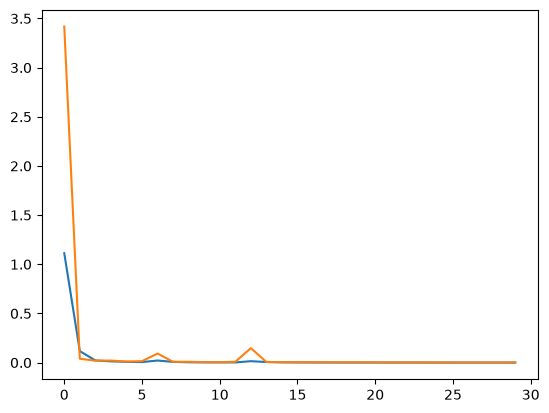

In [6]:
plt.plot(history.history['loss'], label='train_loss')
plt.plot(history.history['val_loss'], label='val_loss')

## 4. Đánh giá trên tập Test

In [7]:
pred_seqs = predict_sequences(model, X_test)
results = evaluate_model(y_test, pred_seqs, model_name='DaiModel')

=== DaiModel ===
R2: 0.9995 | NSE: 0.9995 | MAE: 5889.9567 | RMSE: 427877.0763
